# Setup

In [1]:
from pprint import pprint
from pathlib import Path
from dotenv import dotenv_values


# Config
cfg = dotenv_values()
pprint(cfg)

OrderedDict({'CHAT_SMALL': 'qwen3:0.6b', 'SEED': '42'})


In [ ]:
from typing import TypedDict
from pydantic import BaseModel
from IPython.display import Image

from langchain_ollama import ChatOllama
from langchain.messages import SystemMessage, HumanMessage, ToolMessage
from langchain.tools import tool, ToolRuntime, ToolException
from langchain.agents.middleware import ToolCallLimitMiddleware
from langchain.agents import AgentState, create_agent

from langgraph.types import Command

# 1. Chat

## 1.1. Chat Model

In [3]:
chat = ChatOllama(
    model=cfg['CHAT_SMALL'],
    reasoning=True,
    seed=cfg['SEED'],
)

## 1.2. System Prompt

In [4]:
system_prompt = SystemMessage(
    "You are a helpful assitant."
)

## 1.3. Response Format

In [5]:
class AnswerWithReason(BaseModel):
    """Response the answer with reason."""
    answer: str
    reason: str

# 2. Context

## 2.1. Agent State

In [6]:
class SimpleAgentState(AgentState):
    """Simple agent state."""
    last_sum: int

## 2.2. Runtime Context

In [7]:
class AgentContext(TypedDict):
    """Runtime context."""
    user_id: str

## 2.3. Run Config

In [8]:
config = {
    'configurable': {
        'thread_id': 'test-1',
    }
}

# 3. Tools & Middlewares

## 3.1. Tools

In [ ]:
@tool
def add_ints(
    x: int, y: int,
    runtime: ToolRuntime[AgentContext],
) -> Command:
    """Add two integers and return updated state."""
    user_id = runtime.context['user_id']

    # Exception handling
    if x < 0 or y < 0:
        raise ToolException("Negative integers are not allowed.")

    result = x + y

    return Command(
        update={
            'last_sum': result,
            'messages': [
                ToolMessage(str(result), tool_call_id=runtime.tool_call_id),
            ]
        }
    )


# Allow the agent to handle ToolException
add_ints.handle_tool_error = True

## 3.2. Middlewares

- https://docs.langchain.com/oss/python/langchain/middleware/built-in

### 3.2.1. ToolCallLimitMiddleware

In [10]:
tool_middleware = ToolCallLimitMiddleware(
    tool_name='add_ints',
    run_limit=5,
)

# 4. Memory

In [11]:
from langgraph.checkpoint.memory import InMemorySaver
from langgraph.store.memory import InMemoryStore
from langgraph.cache.memory import InMemoryCache


# Checkpointer
checkpointer = InMemorySaver()      # warning for custom response schema; consider `JsonPlusSerializer.allowed_msgpack_modules`

# Store
store = InMemoryStore()

# Cache
cache = InMemoryCache()

# 4. Agent

In [18]:
agent = create_agent(
    # 1. Chat
    model=chat,
    system_prompt=system_prompt,
    response_format=AnswerWithReason,

    # 2. Context
    state_schema=SimpleAgentState,
    context_schema=AgentContext,

    # 3. Tools & Middlewares
    tools=[add_ints],
    middleware=[tool_middleware],

    # 4. Memory
    checkpointer=checkpointer,
    store=store,
    cache=cache,

    interrupt_before=['tools'],     # interrupt before running a 'tool' node
    interrupt_after=None,

    name='study_agent',

    debug=False,
)

# 5. Response

In [13]:
## Interrupt before using a tool
response = agent.invoke(
    input={
        'messages': [HumanMessage('1 + 2?')],
        'last_sum': 0,
    },
    context={
        'user_id': 'yana',
    },
    config=config,
)
print(f"Paused before: {agent.get_state(config).next}")


# Resume
response = agent.invoke(
    None,
    context={
        'user_id': 'yana',
    },
    config=config,
)

for msg in response['messages']:
    print(f"- {type(msg).__name__:<20s}:\n{msg}\n")

response['last_sum']     # value stored in the agent state

Paused before: ('tools',)
- HumanMessage        :
content='1 + 2?' additional_kwargs={} response_metadata={} id='78548417-fbf4-4861-9e8f-ee134f5bd45a'

- AIMessage           :
content='' additional_kwargs={'reasoning_content': 'Okay, the user is asking 1 plus 2. I need to figure out if they want the answer with a reason or just the sum. Let me check the tools provided. The first tool is add_ints, which adds two integers and returns a state. The second tool is AnswerWithReason, which gives the answer with a reason. Since the user just wants the sum, I should use the add_ints function. But wait, the user\'s question is a simple addition, so maybe they just want the result. However, the instructions say to use the tools if needed. Since there\'s no reason required here, maybe just return the sum. Let me make sure. The add_ints function takes two integers, so x and y. The user\'s input is 1 and 2, so the arguments would be {"x":1, "y":2}. Then the tool call would be for add_ints. But maybe

3

# 6. Visualize

                                      +-----------+                  
                                      | __start__ |                  
                                      +-----------+                  
                                            *                        
                                            *                        
                                            *                        
                                        +-------+                    
                                        | model |                    
                                     ***+-------+....                
                                 ****                ...             
                              ***                       ...          
                            **                             ....      
+-----------------------------------------------+              ..    
| ToolCallLimitMiddleware[add_ints].after_model |               .    
+-------------------

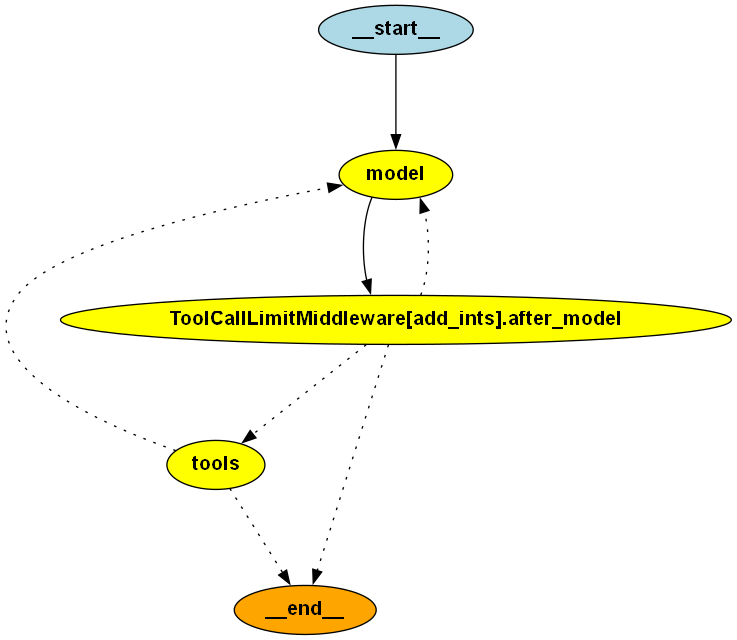

In [14]:
graph = agent.get_graph()
graph.print_ascii()

display(Image(agent.get_graph().draw_png()))